# Marine account: area attribution, physical uptake and BCW

## Purpose and scope

This deep dive follows how coastal ecosystem areas and their uptake rates form the marine physical account, and how that account contributes to Blue Carbon Wealth (BCW). It focuses on mangrove-area attribution and source coverage, then places the mangrove component beside saltmarsh, seagrass and the open-ocean biological carbon pump.

For mangrove area, the current selection is GMW 2025 first, then a reported FRA 2025 value, then the area reported by Hilmi et al. (2026); if none is available, the area remains missing. The notebook inspects the outputs and spatial audits prepared by the main pipeline.

## 1. Start with the current marine account

The main account table contains the selected mangrove area, the component fluxes and BCW valuation. The overlay summary and reconciliation table explain how the GMW 2025 polygon intersections were assigned and corrected. The source ISO code is retained for provenance; the intersected EEZ geometry determines the study unit.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "code" / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository from the notebook working directory.")

ROOT = find_repo_root(Path.cwd().resolve())
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Run this notebook from within the repository.')

DATA = ROOT / 'data' / 'derived'
RESULTS = ROOT / 'results'
TABLES = RESULTS / 'tables' / 'manuscript'
VALIDATION = ROOT / 'data' / 'outputs' / 'validation'
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print(f'Repository: {ROOT}')

Repository: /workspace/ncw


## 2. Keep the coastal ecosystems and ocean pump distinct

The coastal blue-carbon ecosystems (BCEs) are saltmarsh, seagrass and mangrove. The open-ocean biological carbon pump (BCP) is a separate component. The calculation sums the available physical inputs, values the resulting components with the shared GSCC draws, and preserves component availability so the table does not confuse an unavailable input with a reported zero.

In [2]:
# National BCW is calculated from the selected coastal areas and their rates, plus Hilmi's BCP flux, then valued with the shared GSCC draws.
accounts = pd.read_csv(TABLES / 'Supplementary_country_level_accounts_2024.csv')
account_view = accounts[[
    'UNIT_CODE', 'name', 'mangrove_area_selected_ha', 'mangrove_area_source',
    'bcw_sequestration_tco2_yr_mean', 'bcw_usd2015_yr_mean'
]].copy()
account_view = account_view.loc[account_view['bcw_usd2015_yr_mean'].notna()]
account_view = account_view.sort_values('bcw_usd2015_yr_mean', ascending=False)
print('BCW is calculated directly from the available marine areas and fluxes. If no mangrove area source exists, the area remains NaN and the Hilmi-reported BCW draw is retained.')
display(account_view.head(15))


BCW is calculated directly from the available marine areas and fluxes. If no mangrove area source exists, the area remains NaN and the Hilmi-reported BCW draw is retained.


,UNIT_CODE,name,mangrove_area_selected_ha,mangrove_area_source,bcw_sequestration_tco2_yr_mean,bcw_usd2015_yr_mean
250,USA,United States of America,2.536052e+05,GMW_2025,3.059243e+08,1.711825e+11
19,AUS,Australia,1.075088e+06,GMW_2025,2.510315e+08,1.404704e+11
49,CHL,Chile,0.000000e+00,FRA_2025,2.313854e+08,1.294770e+11
200,RUS,Russian Federation,0.000000e+00,FRA_2025,1.752350e+08,9.805708e+10
185,PER,Peru,5.116055e+03,GMW_2025,1.662298e+08,9.301759e+10
86,FRA,France,0.000000e+00,FRA_2025,1.653426e+08,9.252180e+10
112,IDN,Indonesia,3.167637e+06,GMW_2025,1.488788e+08,8.325730e+10
180,NZL,New Zealand,2.752953e+04,GMW_2025,1.313816e+08,7.351706e+10
74,ECU,Ecuador,1.562450e+05,GMW_2025,1.291994e+08,7.229351e+10
114,IND,India,4.695406e+05,GMW_2025,1.286459e+08,7.197999e+10


## 3. Connect area, uptake rate and uncertainty

For a coastal ecosystem, area multiplied by its uptake rate gives annual carbon uptake. The source release supplies 20,000 rate draws for each BCE and 20,000 GSCC draws; a common draw index is used across study units. The rate-draw spread represents uncertainty in the rate input, not uncertainty in the mapped area. GMW 2025 areas use the direct polygon–EEZ intersection and the published 0.9775 correction; fallback areas retain their reported source values.

In [3]:
draws_path = DATA.parent / 'raw' / 'environmental' / 'marine' / 'bcw' / 'output' / 'draws.npz'
marine_draws = np.load(draws_path, allow_pickle=True)
rate_names = ['Saltmarshes', 'Seagrasses', 'Mangroves']
rate_draws = np.asarray(marine_draws['bce_rates_draws'], dtype=float)
gscc_draws = np.asarray(marine_draws['gscc_draws'], dtype=float)
rate_summary = pd.DataFrame({
    'BCE': rate_names,
    'draws': [rate_draws.shape[1]] * len(rate_names),
    'mean_tC_km2_yr': np.nanmean(rate_draws, axis=1),
    'p05_tC_km2_yr': np.nanquantile(rate_draws, 0.05, axis=1),
    'p50_tC_km2_yr': np.nanquantile(rate_draws, 0.50, axis=1),
    'p95_tC_km2_yr': np.nanquantile(rate_draws, 0.95, axis=1),
})
display(rate_summary)
print(f'BCE rate draws: {rate_draws.shape}; GSCC draws: {gscc_draws.shape}')
print('Rate order in the source draws: saltmarshes, seagrasses, mangroves.')

,BCE,draws,mean_tC_km2_yr,p05_tC_km2_yr,p50_tC_km2_yr,p95_tC_km2_yr
0,Saltmarshes,20000,168.000000,168.000000,168.000000,168.000000
1,Seagrasses,20000,218.762774,48.941570,165.339256,564.310825
2,Mangroves,20000,185.266312,23.341217,114.609505,579.337271


BCE rate draws: (3, 20000); GSCC draws: (20000,)
Rate order in the source draws: saltmarshes, seagrasses, mangroves.


## 4. Follow the EEZ and source-row crosswalk

Marine source rows are mapped to the common study-unit key. When several source rows map to the same study unit, their physical marine contributions and draws are summed. This makes the geographic comparison consistent with the forest and national accounts while keeping the original source coverage visible.

In [4]:
availability = np.select(
    [accounts['has_gcw'] & accounts['has_bcw'], accounts['has_gcw'] & ~accounts['has_bcw'], ~accounts['has_gcw'] & accounts['has_bcw']],
    ['GCW and BCW', 'GCW only', 'BCW only'],
    default='Neither account',
)
accounts = pd.concat([accounts, pd.Series(availability, index=accounts.index, name='account_availability')], axis=1)
fra_units = accounts.loc[accounts['unit_class'].eq('FRA country or territory')].copy()
availability_order = ['GCW and BCW', 'GCW only', 'BCW only', 'Neither account']

coverage_table = (
    fra_units['account_availability'].value_counts()
    .reindex(availability_order, fill_value=0)
    .rename_axis('Account availability')
    .reset_index(name='Number of FRA countries and territories')
)
display(coverage_table)

group_table = pd.crosstab(
    fra_units['groups'].fillna('Unclassified'), fra_units['account_availability']
).reindex(columns=availability_order, fill_value=0)
group_table.index.name = 'Economic group'
group_table.columns.name = 'Account availability'
display(group_table)

bcw_crosswalk_units = accounts['unit_class'].eq('BCW-only accounting unit')
print(f'Outside the FRA country and territory set: {int(bcw_crosswalk_units.sum())} BCW-crosswalk units, including {int(accounts.loc[bcw_crosswalk_units, "has_bcw"].sum())} with a BCW estimate and {int((~accounts.loc[bcw_crosswalk_units, "has_gcw"] & ~accounts.loc[bcw_crosswalk_units, "has_bcw"]).sum())} with neither account value.')
print('The group table is restricted to FRA countries and territories; the four economic groups are classifications, not rankings.')

,Account availability,Number of FRA countries and territories
0,GCW and BCW,232
1,GCW only,4
2,BCW only,0
3,Neither account,0


Account availability,GCW and BCW,GCW only,BCW only,Neither account
Economic group,,,,
Developed economies,61,1,0,0
Developing economies,78,2,0,0
LDCs,36,1,0,0
SIDS,57,0,0,0


Outside the FRA country and territory set: 28 BCW-crosswalk units, including 5 with a BCW estimate and 23 with neither account value.
The group table is restricted to FRA countries and territories; the four economic groups are classifications, not rankings.


## 5. Descriptive rankings of the marine account

A ranking is only a descriptive ordering of the current values. It does not change the account definition and it does not mean that the first unit has a higher quality estimate. Here we show three different orderings so that readers do not confuse them:

- total current BCW value, in US$2015 yr⁻¹;
- current coastal physical flux, which includes the updated Selected mangrove area;
- open-ocean BCP physical flux, supplied separately by the BCW source.

The coastal and BCP rankings answer different descriptive questions. A large EEZ or a high coastal ecosystem area can produce a high coastal flux, while the BCP ranking reflects the source's open-ocean allocation. The monetary ranking combines both components through the same GSCC framework.

In [5]:
ranking = accounts.loc[
    accounts['has_bcw'] & accounts['bcw_usd2015_yr_mean'].notna() & ~accounts['exclude_from_country_sum'].fillna(False),
    ['UNIT_CODE', 'name', 'region', 'groups', 'bcw_usd2015_yr_mean',
     'coastal_component_uptake_tC_yr_current_area',
     'open_ocean_bcp_tC_yr_source'],
].copy()
ranking = ranking.rename(columns={
    'bcw_usd2015_yr_mean': 'bcw_value_USD2015_yr_mean',
    'coastal_component_uptake_tC_yr_current_area': 'coastal_flux_tC_yr_actual',
    'open_ocean_bcp_tC_yr_source': 'open_ocean_bcp_flux_tC_yr_source',
})
ranking['total_bcw_flux_tC_yr_actual'] = ranking['coastal_flux_tC_yr_actual'] + ranking['open_ocean_bcp_flux_tC_yr_source']
ranking['coastal_share_of_total_flux_pct'] = (
    ranking['coastal_flux_tC_yr_actual']
    / ranking['total_bcw_flux_tC_yr_actual']
    * 100
)
ranking['rank_BCW'] = ranking['bcw_value_USD2015_yr_mean'].rank(method='min', ascending=False).astype('Int64')
ranking['rank_coastal_flux'] = ranking['coastal_flux_tC_yr_actual'].rank(method='min', ascending=False).astype('Int64')
ranking['rank_BCP_flux'] = ranking['open_ocean_bcp_flux_tC_yr_source'].rank(method='min', ascending=False).astype('Int64')
display(ranking.sort_values('bcw_value_USD2015_yr_mean', ascending=False).head(15))
print('The table is ordered by monetary BCW value in US$2015 per year. Coastal and open-ocean fluxes are in tC per year; coastal flux uses the selected mangrove area under the source hierarchy, while open-ocean BCP remains from the source account.')

,UNIT_CODE,name,region,groups,bcw_value_USD2015_yr_mean,coastal_flux_tC_yr_actual,open_ocean_bcp_flux_tC_yr_source,total_bcw_flux_tC_yr_actual,coastal_share_of_total_flux_pct,rank_BCW,rank_coastal_flux,rank_BCP_flux
250,USA,United States of America,Americas,Developed economies,1.711825e+11,3.788295e+06,79645600.0,8.343390e+07,4.540475,1,8,1
19,AUS,Australia,Oceania,Developed economies,1.404704e+11,1.319081e+07,55272322.0,6.846314e+07,19.267032,2,2,3
49,CHL,Chile,Americas,Developing economies,1.294770e+11,1.547491e+03,63103556.0,6.310510e+07,0.002452,3,147,2
200,RUS,Russian Federation,Europe,Developed economies,9.805708e+10,1.332142e+06,46459217.0,4.779136e+07,2.787412,4,19,4
185,PER,Peru,Americas,Developing economies,9.301759e+10,5.696683e+04,45278430.0,4.533540e+07,0.125656,5,97,5
86,FRA,France,Europe,Developed economies,9.252180e+10,3.739701e+05,44719481.0,4.509345e+07,0.829322,6,47,6
112,IDN,Indonesia,Asia,Developing economies,8.325730e+10,9.718150e+06,30885166.0,4.060332e+07,23.934375,7,3,10
180,NZL,New Zealand,Oceania,Developed economies,7.351706e+10,7.925916e+04,35752087.0,3.583135e+07,0.221201,8,91,7
74,ECU,Ecuador,Americas,Developing economies,7.229351e+10,2.894839e+05,34946708.0,3.523619e+07,0.821553,9,55,8
114,IND,India,Asia,Developing economies,7.197999e+10,1.795133e+06,33290126.0,3.508526e+07,5.116487,10,15,9


The table is ordered by monetary BCW value in US$2015 per year. Coastal and open-ocean fluxes are in tC per year; coastal flux uses the selected mangrove area under the source hierarchy, while open-ocean BCP remains from the source account.


## 6. Audit mangrove-area attribution

The direct GMW overlay reports raw geometric intersections; the account-area output applies the 0.9775 factor before aggregating those intersections to study units. Compare raw and corrected totals, selected source counts, and the units whose selected area can be compared with a previous reported value. Differences between summed EEZ intersections and a global map total may also reflect overlapping EEZ geometries.

In [6]:
accounts = pd.read_csv(TABLES / 'Supplementary_country_level_accounts_2024.csv')
gmw_summary = json.loads((VALIDATION / 'gmw_2025_direct_overlay_summary.json').read_text(encoding='utf-8'))
area_audit = pd.read_csv(VALIDATION / 'gmw_2025_direct_area_by_account_iso3.csv')
area_provenance = json.loads((DATA / 'gmw_2025_mangrove_area_provenance.json').read_text(encoding='utf-8'))
mangrove_audit = pd.read_csv(TABLES / 'Supplementary_mangrove_reconciliation.csv')

selected_area = pd.to_numeric(accounts['mangrove_area_selected_ha'], errors='coerce')
print('Units with a selected mangrove area:', int(selected_area.notna().sum()))
print('Units with no selected area (missing/NaN):', int(selected_area.isna().sum()))
print('Sum of known selected areas (ha):', float(selected_area.sum(min_count=1)))
print('Area source counts:')
display(mangrove_audit['mangrove_area_source'].value_counts(dropna=False).rename_axis('source').to_frame('units'))
comparable = mangrove_audit['mangrove_area_comparable_to_hilmi'].fillna(False).astype(bool)
changed = mangrove_audit['mangrove_area_changed_from_hilmi'].fillna(False).astype(bool)
print('Units with selected and Hilmi-reported areas:', int(comparable.sum()))
print('Units where those two areas differ:', int((comparable & changed).sum()))
print('Raw direct-intersection area across account units (ha):', float(area_audit['gmw_2025_mangrove_area_raw_ha'].sum()))
print('GMW global area correction factor:', area_provenance['area_correction_factor'])
print('Corrected GMW area across account units (ha):', float(area_audit['gmw_2025_mangrove_area_ha'].sum()))
summary_fields = ['method', 'area_basis', 'area_correction_applied_in_overlay', 'area_crs', 'gmw_features_total', 'gmw_features_processed', 'eez_union_units', 'gmw_source_codes_observed', 'intersection_pairs', 'units_with_intersections', 'gmw_features_without_positive_area_intersection', 'total_direct_overlay_area_ha_summed_across_union_units', 'cross_source_overlap_excess_ha']
display(pd.Series({key: gmw_summary[key] for key in summary_fields}, name='value').to_frame())
mangrove_display_names = {
    'mangrove_area_selected_ha': 'selected_mangrove_area_ha',
    'selected_mangrove_uptake_tC_yr_mean': 'mangrove_flux_tC_yr',
    'selected_mangrove_uptake_tCO2_yr_mean': 'mangrove_flux_tCO2_yr',
    'selected_mangrove_uptake_tC_yr_p05': 'mangrove_flux_tC_yr_p05',
    'selected_mangrove_uptake_tC_yr_p50': 'mangrove_flux_tC_yr_p50',
    'selected_mangrove_uptake_tC_yr_p95': 'mangrove_flux_tC_yr_p95',
    'bcw_sequestration_tco2_yr_mean': 'bcw_total_flux_tCO2_yr_mean',
    'bcw_usd2015_yr_mean': 'bcw_value_USD2015_yr_mean',
}
display(mangrove_audit.head(12).rename(columns=mangrove_display_names))


Units with a selected mangrove area: 236
Units with no selected area (missing/NaN): 30
Sum of known selected areas (ha): 14817946.054540467
Area source counts:


,units
source,
GMW_2025,126
FRA_2025,66
no_source_available,16


Units with selected and Hilmi-reported areas: 118
Units where those two areas differ: 118
Raw direct-intersection area across account units (ha): 15156239.074164072
GMW global area correction factor: 0.9775
Corrected GMW area across account units (ha): 14815223.694995381


,value
method,Project and validate GMW and EEZ geometries in...
area_basis,Raw mapped polygon area before GMW's global ac...
area_correction_applied_in_overlay,False
area_crs,ESRI:54009 (Mollweide)
gmw_features_total,1551714
gmw_features_processed,1551714
eez_union_units,328
gmw_source_codes_observed,129
intersection_pairs,204
units_with_intersections,136


,UNIT_CODE,ISO3,name,region,iso3,fra_mangroves_2025_ha,documented_forest_fraction,documented_forest_mangrove_area_ha,documented_other_wooded_land_fraction,documented_other_wooded_land_area_ha,documented_remaining_land_fraction,documented_remaining_land_area_ha,unresolved_mangrove_area_ha,overlap_status,desk_study,fra_report_handle,fra_report_url,evidence_note,report_excerpt,gmw_2025_mangrove_area_raw_ha,gmw_2025_mangrove_area_ha,groups,fra_total_forest_area_2025_ha,fra_mangrove_category_2025_ha,fra_naturally_regenerating_forest_2025_ha,hilmi_2026_mangroves_ha,selected_mangrove_area_ha,mangrove_area_source,mangrove_area_source_updated_from_hilmi,mangrove_area_changed_from_hilmi,mangrove_area_new_where_hilmi_missing,mangrove_area_comparable_to_hilmi,mangrove_flux_tC_yr,mangrove_flux_tCO2_yr,mangrove_flux_tC_yr_p05,mangrove_flux_tC_yr_p50,mangrove_flux_tC_yr_p95,bcw_total_flux_tCO2_yr_mean,bcw_value_USD2015_yr_mean,accounting_note
0,ABW,ABW,Aruba,Caribbean,ABW,70.0,NaN,0.0,NaN,0.0,NaN,0.0,70.0,no_exact_forest_split_verified,Yes,A03278EN,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,Original data | The forest area is estimated u...,116.318193,113.701034,SIDS,490.0,70.0,490.0,43.294220,113.701034,GMW_2025,True,True,False,True,210.649712,772.382278,26.539205,130.312192,658.712467,2.731239e+04,1.529748e+07,FRA mangrove hectares are removed from GCW onl...
1,AGO,AGO,Angola,Africa,AGO,27920.0,NaN,0.0,NaN,0.0,NaN,0.0,27920.0,no_exact_forest_split_verified,No,A03636FR,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,NaN,29425.063078,28762.999159,LDCs,63262330.0,27920.0,63206690.0,28065.293510,28762.999160,GMW_2025,True,True,False,True,53288.147730,195389.875000,6713.633979,32965.130870,166634.774400,4.467094e+07,2.499639e+10,FRA mangrove hectares are removed from GCW onl...
2,AIA,AIA,Anguilla,Caribbean,AIA,90.0,NaN,0.0,NaN,0.0,NaN,0.0,90.0,no_exact_forest_split_verified,Yes,A03275EN,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,NaN,8.291808,8.105243,SIDS,5500.0,90.0,NaN,3.527194,8.105243,GMW_2025,True,True,False,True,15.016284,55.059709,1.891862,9.289379,46.956692,1.209504e+04,6.775323e+06,FRA mangrove hectares are removed from GCW onl...
3,ALB,ALB,Albania,Europe,ALB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,Developed economies,941000.0,0.0,NaN,NaN,0.000000,FRA_2025,True,False,True,False,0.000000,0.000000,0.000000,0.000000,0.000000,3.496346e+05,1.956678e+08,FRA mangrove hectares are removed from GCW onl...
4,ARE,ARE,United Arab Emirates,Asia,ARE,13610.0,NaN,0.0,NaN,0.0,NaN,0.0,13610.0,no_exact_forest_split_verified,Yes,A03544EN,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,2003 | Date palm 185.30 0.000 % 0.000 % 100.00...,9923.922230,9700.633980,Developing economies,324580.0,13610.0,310970.0,7386.247415,9700.633980,GMW_2025,True,True,False,True,17972.006810,65897.358290,2264.246004,11117.848560,56199.388180,9.148419e+05,5.122423e+08,FRA mangrove hectares are removed from GCW onl...
5,ARG,ARG,Argentina,Americas,ARG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,Developing economies,46609000.0,0.0,45282000.0,NaN,0.000000,FRA_2025,True,False,True,False,0.000000,0.000000,0.000000,0.000000,0.000000,3.909656e+07,2.187738e+10,FRA mangrove hectares are removed from GCW onl...
6,ASM,ASM,American Samoa,Oceania,ASM,20.0,NaN,0.0,NaN,0.0,NaN,0.0,20.0,no_exact_forest_split_verified,No,A03274EN,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,NaN,34.440943,33.666022,SIDS,15850.0,20.0,15850.0,31.891920,33.666022,GMW_2025,True,True,False,True,62.371797,228.696588,7.858059,38.584461,195.039811,3.700746e+05,2.073110e+08,FRA mangrove hectares are removed from GCW onl...
7,ATF-1,NaN,Amsterdam and Saint Paul Islands,Africa,ATF-1,NaN,NaN,NaN,N

### Visual summary: area source and selected mangrove uptake

The left panel shows how many study units receive each selected mangrove-area source. The right panel compares selected area with its corresponding annual mangrove uptake for units with both values. These are coverage and arithmetic views, not an assessment of map accuracy.

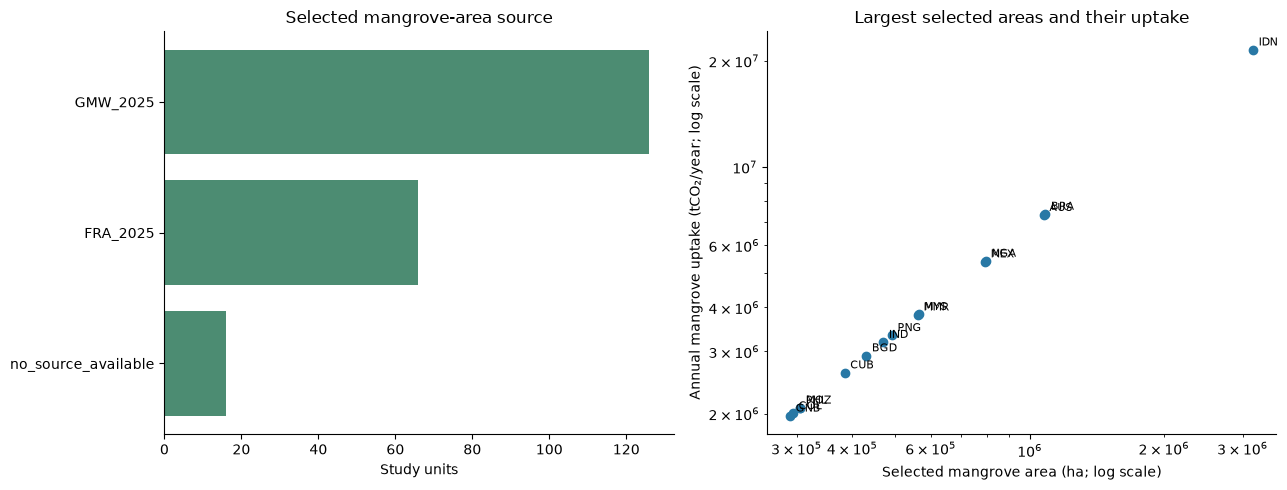

In [7]:
source_counts = mangrove_audit["mangrove_area_source"].fillna("Unavailable").astype(str).value_counts()
mangrove_plot = accounts.copy()
mangrove_plot["selected_area_ha"] = pd.to_numeric(mangrove_plot["mangrove_area_selected_ha"], errors="coerce")
mangrove_plot["uptake_tco2_yr"] = pd.to_numeric(mangrove_plot["selected_mangrove_uptake_tCO2_yr_mean"], errors="coerce")
mangrove_plot = mangrove_plot.loc[mangrove_plot["selected_area_ha"].gt(0) & mangrove_plot["uptake_tco2_yr"].gt(0)]
mangrove_plot = mangrove_plot.nlargest(15, "selected_area_ha")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(source_counts.index[::-1], source_counts.values[::-1], color="#4C8C72")
axes[0].set_xlabel("Study units")
axes[0].set_title("Selected mangrove-area source")
axes[1].scatter(mangrove_plot["selected_area_ha"], mangrove_plot["uptake_tco2_yr"], color="#2878A5")
for row in mangrove_plot.itertuples():
    axes[1].annotate(row.UNIT_CODE, (row.selected_area_ha, row.uptake_tco2_yr), xytext=(4, 3), textcoords="offset points", fontsize=8)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Selected mangrove area (ha; log scale)")
axes[1].set_ylabel("Annual mangrove uptake (tCO₂/year; log scale)")
axes[1].set_title("Largest selected areas and their uptake")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 7. Inspect the unit-level distribution

The ranked view helps locate study units with large selected mangrove areas and their corresponding physical uptake. Read it together with the source-count plot: a high value is a result of the selected area and rate, while missing values indicate that the source chain did not provide an area.

In [8]:
area_col = "mangrove_area_selected_ha"
mangrove_value_col = "selected_mangrove_uptake_tCO2_yr_mean"
selected_area = pd.to_numeric(accounts[area_col], errors="coerce")
unit_view = accounts.loc[selected_area.gt(0), ["UNIT_CODE", "name", area_col, mangrove_value_col]].copy()
unit_view[area_col] = pd.to_numeric(unit_view[area_col], errors="coerce")
unit_view[mangrove_value_col] = pd.to_numeric(unit_view[mangrove_value_col], errors="coerce")
display(unit_view.sort_values(area_col, ascending=False).head(15).rename(columns=mangrove_display_names))


,UNIT_CODE,name,selected_mangrove_area_ha,mangrove_flux_tCO2_yr
112,IDN,Indonesia,3.167637e+06,2.151807e+07
39,BRA,Brazil,1.083926e+06,7.363218e+06
19,AUS,Australia,1.075088e+06,7.303180e+06
173,NGA,Nigeria,7.978092e+05,5.419596e+06
152,MEX,Mexico,7.941859e+05,5.394983e+06
167,MYS,Malaysia,5.633276e+05,3.826740e+06
157,MMR,Myanmar,5.615945e+05,3.814967e+06
188,PNG,Papua New Guinea,4.909286e+05,3.334926e+06
114,IND,India,4.695406e+05,3.189635e+06
29,BGD,Bangladesh,4.301320e+05,2.921929e+06


## 8. Place the marine result beside GCW and NCW

The global table shows how the updated marine account sits beside the forest and combined accounts. It also exposes the coverage counts, so a change in the total can be read alongside the number of units with available account components.

In [9]:
global_table = pd.read_csv(TABLES / 'Table1_global_carbon_wealth.csv')
display(global_table)

,component,value_mean_trillion_usd2015_yr,value_p05_trillion_usd2015_yr,value_p50_trillion_usd2015_yr,value_p95_trillion_usd2015_yr,share_of_ncw_pct,gcw_records,bcw_records_including_source_aggregate,bcw_country_or_territory_records,units_with_both_accounts,records_with_either_account,aggregation_scope
0,Green carbon wealth,8.261443,3.226506,7.481159,14.999199,78.00619,236,238,237,232,242,Available component total across all GCW units.
1,Blue carbon wealth,2.329310,0.909103,2.113419,4.297955,21.99381,236,238,237,232,242,Available component total; BCW includes the so...
2,Natural carbon wealth,10.590753,4.163877,9.600823,19.204479,100.00000,236,238,237,232,242,Global and unit-level NCW sum available compon...


## 9. Review cross-source and boundary cases

Use the reconciliation table to inspect mismatched source codes, unassigned area, and boundary overlaps. These are attribution and coverage diagnostics; a missing intersection does not establish that a place has no mangroves.

In [10]:
audit_cols = [c for c in mangrove_audit.columns if any(k in c.lower() for k in ['iso', 'name', 'area', 'status', 'fra', 'gmw', 'overlap', 'note'])]
display(mangrove_audit[audit_cols].head(30).rename(columns=mangrove_display_names))

,ISO3,name,iso3,fra_mangroves_2025_ha,documented_forest_fraction,documented_forest_mangrove_area_ha,documented_other_wooded_land_fraction,documented_other_wooded_land_area_ha,documented_remaining_land_fraction,documented_remaining_land_area_ha,unresolved_mangrove_area_ha,overlap_status,fra_report_handle,fra_report_url,evidence_note,gmw_2025_mangrove_area_raw_ha,gmw_2025_mangrove_area_ha,fra_total_forest_area_2025_ha,fra_mangrove_category_2025_ha,fra_naturally_regenerating_forest_2025_ha,selected_mangrove_area_ha,mangrove_area_source,mangrove_area_source_updated_from_hilmi,mangrove_area_changed_from_hilmi,mangrove_area_new_where_hilmi_missing,mangrove_area_comparable_to_hilmi,accounting_note
0,ABW,Aruba,ABW,70.0,NaN,0.0,NaN,0.0,NaN,0.0,70.0,no_exact_forest_split_verified,A03278EN,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,1.163182e+02,1.137010e+02,490.0,70.0,490.0,1.137010e+02,GMW_2025,True,True,False,True,FRA mangrove hectares are removed from GCW onl...
1,AGO,Angola,AGO,27920.0,NaN,0.0,NaN,0.0,NaN,0.0,27920.0,no_exact_forest_split_verified,A03636FR,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,2.942506e+04,2.876300e+04,63262330.0,27920.0,63206690.0,2.876300e+04,GMW_2025,True,True,False,True,FRA mangrove hectares are removed from GCW onl...
2,AIA,Anguilla,AIA,90.0,NaN,0.0,NaN,0.0,NaN,0.0,90.0,no_exact_forest_split_verified,A03275EN,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,8.291808e+00,8.105243e+00,5500.0,90.0,NaN,8.105243e+00,GMW_2025,True,True,False,True,FRA mangrove hectares are removed from GCW onl...
3,ALB,Albania,ALB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,0.000000e+00,941000.0,0.0,NaN,0.000000e+00,FRA_2025,True,False,True,False,FRA mangrove hectares are removed from GCW onl...
4,ARE,United Arab Emirates,ARE,13610.0,NaN,0.0,NaN,0.0,NaN,0.0,13610.0,no_exact_forest_split_verified,A03544EN,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,9.923922e+03,9.700634e+03,324580.0,13610.0,310970.0,9.700634e+03,GMW_2025,True,True,False,True,FRA mangrove hectares are removed from GCW onl...
5,ARG,Argentina,ARG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,0.000000e+00,46609000.0,0.0,45282000.0,0.000000e+00,FRA_2025,True,False,True,False,FRA mangrove hectares are removed from GCW onl...
6,ASM,American Samoa,ASM,20.0,NaN,0.0,NaN,0.0,NaN,0.0,20.0,no_exact_forest_split_verified,A03274EN,https://openknowledge.fao.org/handle/20.500.14...,No matching exact national Forest/OWL area spl...,3.444094e+01,3.366602e+01,15850.0,20.0,15850.0,3.366602e+01,GMW_2025,True,True,False,True,FRA mangrove hectares are removed from GCW onl...
7,NaN,Amsterdam and Saint Paul Islands,ATF-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,0.000000e+00,NaN,NaN,NaN,NaN,no_source_available,False,False,False,False,FRA mangrove hectares are removed from GCW onl...
8,NaN,Bassas da India,ATF-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,0.000000e+00,NaN,NaN,NaN,NaN,no_source_available,False,False,False,False,FRA mangrove hectares are removed from GCW onl...
9,NaN,Crozet Islands,ATF-3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,0.000000e+00,NaN,NaN,NaN,NaN,no_source_available,False,False,False,False,FRA mangrove hectares are removed from GCW onl...
